## Klasifikasi Topik Artikel Klarifikasi Hoaks Komdigi

Notebook ini menggunakan teks `title`, `excerpt`, dan `body_text` untuk memprediksi kategori `topics` dengan TF-IDF dan LinearSVC. Kolom `topics` adalah kategori/topik artikel, bukan label benar atau salahnya klaim.


In [1]:
# Import package
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

In [2]:
# Cari dataset dari direktori kerja notebook hingga root proyek.
data_path = next(
    (
        parent / "data" / "komdigi_hoaks.csv"
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "data" / "komdigi_hoaks.csv").is_file()
    ),
    None,
)
if data_path is None:
    raise FileNotFoundError("File data/komdigi_hoaks.csv tidak ditemukan dari direktori kerja saat ini.")

data = pd.read_csv(data_path)
required_columns = ["url", "title", "excerpt", "body_text", "topics"]
missing_columns = [column for column in required_columns if column not in data.columns]
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan pada dataset: {missing_columns}")

# Hapus artikel duplikat dan siapkan gabungan teks untuk klasifikasi.
data = data.drop_duplicates(subset="url", keep="first").dropna(subset=["topics"]).copy()
text_columns = ["title", "excerpt", "body_text"]
data[text_columns] = data[text_columns].fillna("").astype(str)
data["article_text"] = (
    data[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
data = data.loc[data["article_text"].ne("")].reset_index(drop=True)

print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran dataset setelah menghapus duplikat:", data.shape)
display(data[["topics", "title", "excerpt"]].head())
print("Distribusi label topics:")
display(data["topics"].value_counts().rename_axis("topics").to_frame("jumlah"))
data.info()

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran dataset setelah menghapus duplikat: (4162, 14)


,topics,title,excerpt
0,Hoaks,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Kepala Biro Humas Kementerian Ketenagakerjaan ...
1,Hoaks,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,El Nino merupakan fenomena alam yang terjadi a...
2,Hoaks,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Maltodekstrin merupakan bahan tambahan pangan ...
3,Hoaks,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,
4,Hoaks,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,


Distribusi label topics:


,jumlah
topics,
Hoaks,3524
Penipuan,286
Pejabat Publik,135
Masyarakat Digital,102
Program/Kebijakan,59
Kesehatan,56


<class 'pandas.DataFrame'>
RangeIndex: 4162 entries, 0 to 4161
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              4162 non-null   int64
 1   url             4162 non-null   str  
 2   title           4162 non-null   str  
 3   slug            4162 non-null   str  
 4   published_at    4162 non-null   str  
 5   view_count      4162 non-null   int64
 6   excerpt         4162 non-null   str  
 7   body_html       4162 non-null   str  
 8   body_text       4162 non-null   str  
 9   main_image_url  4157 non-null   str  
 10  category        4162 non-null   str  
 11  tags            2187 non-null   str  
 12  topics          4162 non-null   str  
 13  article_text    4162 non-null   str  
dtypes: int64(2), str(12)
memory usage: 17.5 MB


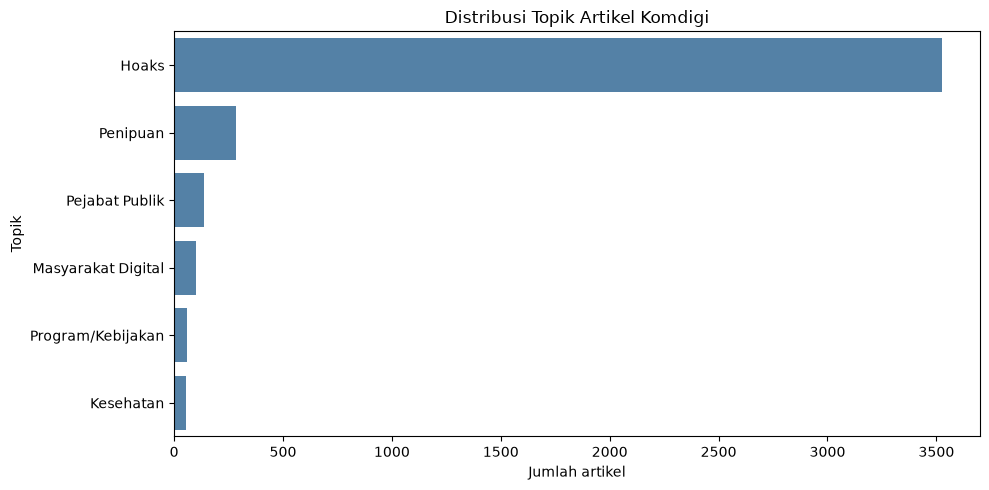

In [3]:
# Visualisasi distribusi kelas.
plt.figure(figsize=(10, 5))
order = data["topics"].value_counts().index
sns.countplot(data=data, y="topics", order=order, color="steelblue")
plt.title("Distribusi Topik Artikel Komdigi")
plt.xlabel("Jumlah artikel")
plt.ylabel("Topik")
plt.tight_layout()
plt.show()

In [4]:
# Fitur berupa teks artikel; target berupa kategori topics.
X = data["article_text"]
y = data["topics"]

# Pembagian data latih dan data uji 75:25 dengan proporsi kelas terjaga.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 3121
Jumlah data uji: 1041


In [5]:
# TF-IDF mengubah teks menjadi fitur numerik, lalu LinearSVC
# memprediksi kategori topik. Bobot kelas membantu menangani label tidak seimbang.
model = Pipeline(
    [
        (
            "tfidf",
            TfidfVectorizer(
                max_features=10000,
                min_df=2,
                ngram_range=(1, 2),
                sublinear_tf=True,
            ),
        ),
        (
            "classifier",
            LinearSVC(
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)
model.fit(X_train, y_train)
print("Akurasi data latih:", round(model.score(X_train, y_train), 4))

Akurasi data latih: 0.9881


In [6]:
# Evaluasi prediksi pada data uji yang tidak digunakan saat pelatihan.
y_pred = model.predict(X_test)
labels = sorted(y.unique())
print("Akurasi data uji:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1-score:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("\nLaporan klasifikasi:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=labels,
        target_names=labels,
        zero_division=0,
    )
)

Akurasi data uji: 0.8367
Macro F1-score: 0.4124

Laporan klasifikasi:
                    precision    recall  f1-score   support

             Hoaks       0.90      0.92      0.91       881
         Kesehatan       0.36      0.29      0.32        14
Masyarakat Digital       0.25      0.08      0.12        25
    Pejabat Publik       0.53      0.53      0.53        34
          Penipuan       0.44      0.53      0.48        72
 Program/Kebijakan       0.50      0.07      0.12        15

          accuracy                           0.84      1041
         macro avg       0.50      0.40      0.41      1041
      weighted avg       0.83      0.84      0.83      1041



In [7]:
# Bandingkan performa model pada data latih dan data uji untuk memeriksa overfitting.
y_train_pred = model.predict(X_train)
print("Akurasi data latih:", round(accuracy_score(y_train, y_train_pred), 4))
print("Macro F1-score data latih:", round(f1_score(y_train, y_train_pred, average="macro", zero_division=0), 4))

Akurasi data latih: 0.9881
Macro F1-score data latih: 0.9764


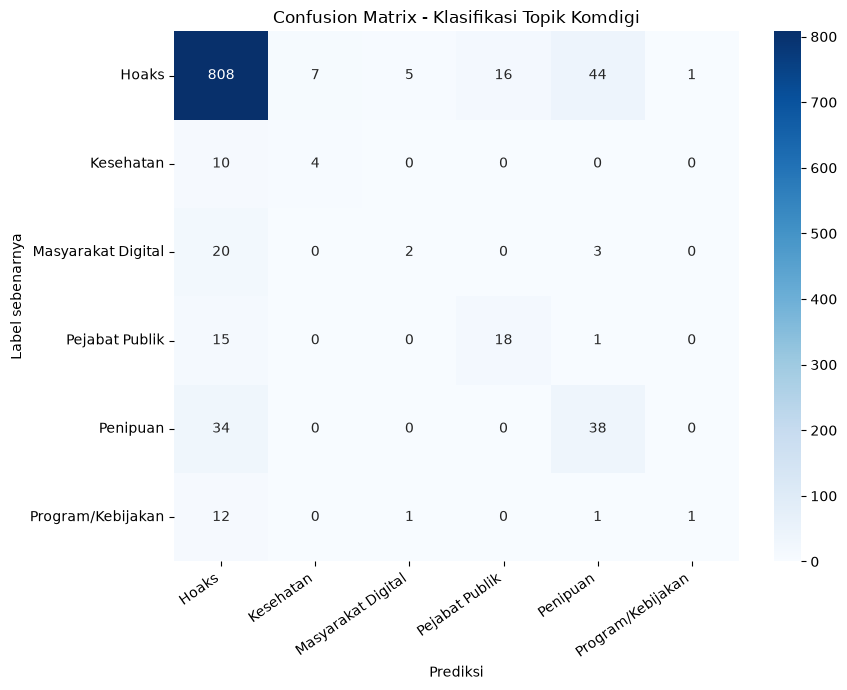

In [8]:
# Matriks kebingungan memperlihatkan kategori yang sering tertukar.
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)
plt.title("Confusion Matrix - Klasifikasi Topik Komdigi")
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# Bandingkan kategori sebenarnya dan prediksi pada beberapa artikel uji.
hasil_prediksi = data.loc[X_test.index, ["title", "topics"]].rename(
    columns={"topics": "topics_asli"}
).copy()
hasil_prediksi["topics_prediksi"] = y_pred
display(hasil_prediksi.head(10))

,title,topics_asli,topics_prediksi
2657,[HOAKS] Akun WhatsApp Mengatasnamakan Sekcam B...,Hoaks,Pejabat Publik
2790,[HOAKS] Poster Peringatan Penculikan Anak dari...,Hoaks,Hoaks
2957,[HOAKS] Hotman Paris Hutapea Bagi-bagi Uang un...,Masyarakat Digital,Penipuan
165,[HOAKS] Tautan Pendaftaran Lapak UMKM di IKN,Hoaks,Hoaks
508,[HOAKS] Kemenag Sarankan Seskab Teddy Jadi Wak...,Hoaks,Hoaks
1826,[HOAKS] Pemerintah Resmi Mengembalikan Sitaan ...,Hoaks,Hoaks
3540,[HOAKS] Informasi KUR BRI Menyertakan Nomor W...,Hoaks,Hoaks
3994,[HOAKS] Akun WhatsApp Mengatasnamakan Setda Ka...,Pejabat Publik,Pejabat Publik
1393,[HOAKS] Video Presiden Rusia Vladimir Putin M...,Hoaks,Hoaks
3013,[HOAKS] Aparat Tewas saat Mengamankan Aksi Dem...,Masyarakat Digital,Hoaks
